# Laboratorio 11 — Analítica longitudinal

Análisis temporal de la base clínica Synthea mediante CTEs,
funciones de ventana y DuckDB.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

evidence = Path("../evidencias")

plt.style.use("seaborn-v0_8-whitegrid")

## Episodios de tratamiento

Se representan las duraciones de los episodios de lisinopril
con un gap de persistencia de 30 días.

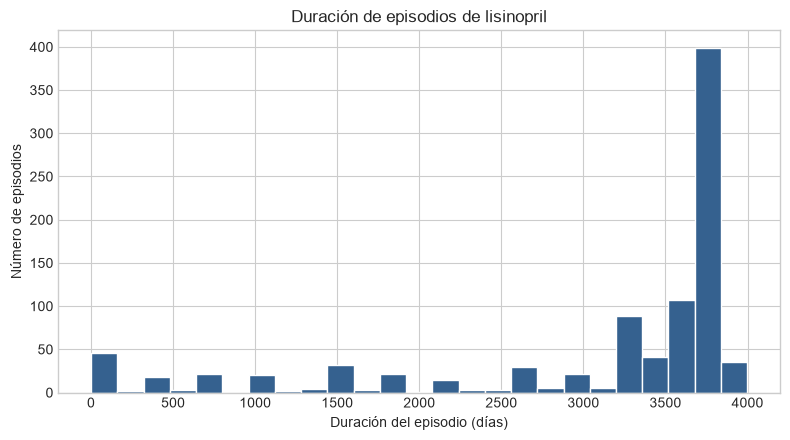

count     927.000000
mean     3034.977346
std      1132.634736
min         1.000000
25%      2939.000000
50%      3655.000000
75%      3711.000000
max      3998.000000
Name: duration_days, dtype: float64

In [2]:
episodes = pd.read_csv(
    evidence / "06_lisinopril_episodes.csv"
)

duration_candidates = [
    column
    for column in (
        "duration_days",
        "episode_duration_days",
    )
    if column in episodes.columns
]

if len(duration_candidates) != 1:
    raise RuntimeError(
        f"Columna de duración no identificada: "
        f"{list(episodes.columns)}"
    )

duration_column = duration_candidates[0]

episodes_30 = episodes.loc[
    episodes["gap_days"] == 30
]

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(
    episodes_30[duration_column],
    bins=25,
    color="#35618f",
    edgecolor="white",
)

ax.set(
    title="Duración de episodios de lisinopril",
    xlabel="Duración del episodio (días)",
    ylabel="Número de episodios",
)

plt.tight_layout()
plt.show()

episodes_30[
    duration_column
].describe()

## Comparación de gaps

Se comparan gaps de 30, 60 y 90 días para determinar
cuánto cambia la construcción de episodios.

,gap_days,episodes,patients,median_duration_days,mean_duration_days,maximum_duration_days
0,30,927,927,3655.0,3034.977346,3998
1,60,927,927,3655.0,3034.977346,3998
2,90,927,927,3655.0,3034.977346,3998


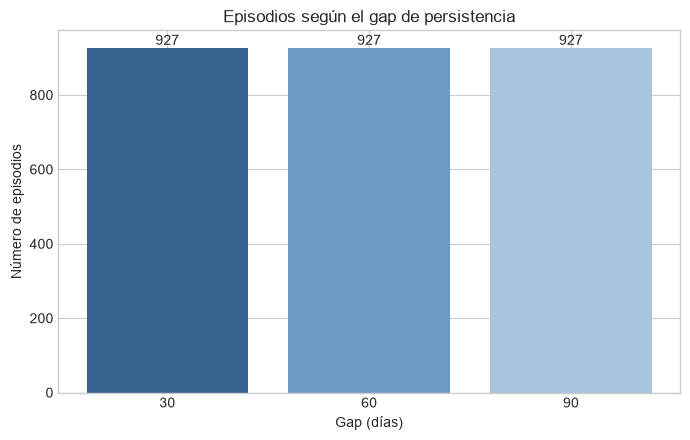

In [3]:
gaps = pd.read_csv(
    evidence / "06_lisinopril_gaps.csv"
)

display(gaps)

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.bar(
    gaps["gap_days"].astype(str),
    gaps["episodes"],
    color=["#35618f", "#6b9ac4", "#a8c4df"],
)

ax.set(
    title="Episodios según el gap de persistencia",
    xlabel="Gap (días)",
    ylabel="Número de episodios",
)

ax.bar_label(ax.containers[0])

plt.tight_layout()
plt.show()

## Media acumulada y media móvil

La media acumulada utiliza toda la historia previa. La media
móvil utiliza solamente las tres mediciones más recientes.

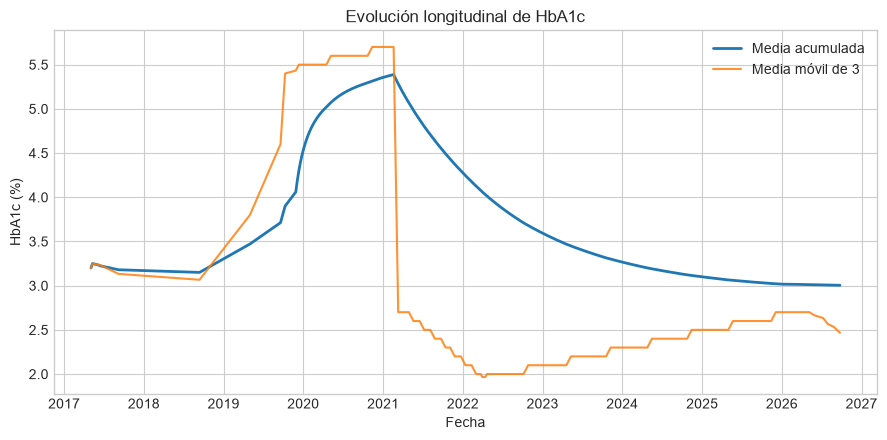

,patient_id,observation_time,hba1c_value,units,cumulative_mean,moving_mean_3
0,8414196a-aded-bdf2-9910-248a10d07a5e,2017-05-03 22:51:44-05:00,3.2,%,3.200000,3.200000
1,8414196a-aded-bdf2-9910-248a10d07a5e,2017-05-10 22:51:44-05:00,3.3,%,3.250000,3.250000
2,8414196a-aded-bdf2-9910-248a10d07a5e,2017-06-07 22:51:44-05:00,3.2,%,3.233333,3.233333
3,8414196a-aded-bdf2-9910-248a10d07a5e,2017-06-14 22:51:44-05:00,3.2,%,3.225000,3.233333
4,8414196a-aded-bdf2-9910-248a10d07a5e,2017-09-06 22:51:44-05:00,3.0,%,3.180000,3.133333
5,8414196a-aded-bdf2-9910-248a10d07a5e,2018-09-12 22:51:44-05:00,3.0,%,3.150000,3.066667
6,8414196a-aded-bdf2-9910-248a10d07a5e,2019-05-01 22:51:44-05:00,5.4,%,3.471429,3.800000
7,8414196a-aded-bdf2-9910-248a10d07a5e,2019-09-18 22:51:44-05:00,5.4,%,3.712500,4.600000
8,8414196a-aded-bdf2-9910-248a10d07a5e,2019-10-09 22:51:44-05:00,5.4,%,3.900000,5.400000
9,8414196a-aded-bdf2-9910-248a10d07a5e,2019-11-27 21:51:44-06:00,5.5,%,4.060000,5.433333


In [4]:
hba1c = pd.read_csv(
    evidence / "08_hba1c_medias.csv",
    parse_dates=["observation_time"],
)

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    hba1c["observation_time"],
    hba1c["cumulative_mean"],
    label="Media acumulada",
    linewidth=2,
)

ax.plot(
    hba1c["observation_time"],
    hba1c["moving_mean_3"],
    label="Media móvil de 3",
    linewidth=1.5,
    alpha=0.85,
)

ax.set(
    title="Evolución longitudinal de HbA1c",
    xlabel="Fecha",
    ylabel="HbA1c (%)",
)

ax.legend()
plt.tight_layout()
plt.show()

hba1c.head(12)

## Rendimiento: ventana contra self-join

Ambas consultas deben producir el mismo resultado clínico.
Se compara la mediana de cinco ejecuciones.

,version,comparable_intervals,median_days,repetitions,minimum_ms,median_ms,maximum_ms,self_join_to_window_ratio
0,window,347430,14.0,5,43.794041,45.578791,46.991875,11.596273
1,self_join,347430,14.0,5,521.921958,528.544083,535.788000,11.596273


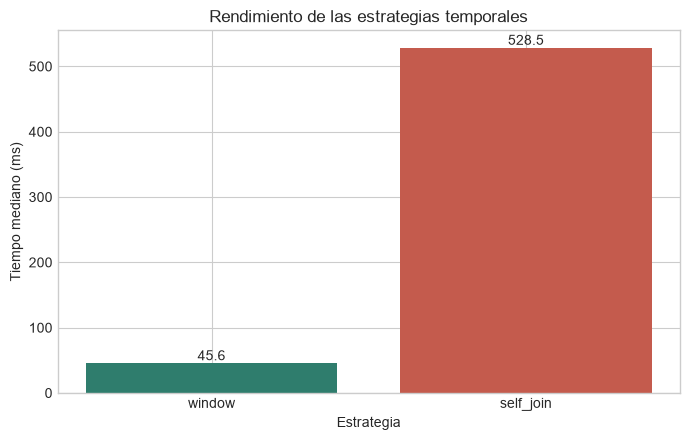

In [5]:
performance = pd.read_csv(
    evidence / "10_performance.csv"
)

display(performance)

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.bar(
    performance["version"],
    performance["median_ms"],
    color=["#2f7d6d", "#c45b4d"],
)

ax.set(
    title="Rendimiento de las estrategias temporales",
    xlabel="Estrategia",
    ylabel="Tiempo mediano (ms)",
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f",
)

plt.tight_layout()
plt.show()

## Conclusiones

- El gap elegido no modificó los episodios en estos datos.
- La media móvil responde más rápido a cambios recientes.
- `LAG` fue más legible y considerablemente más rápido que
  el self-join.
- Los valores basales posteriores al índice se excluyeron para
  evitar fuga de información.